<a href="https://colab.research.google.com/github/joseandres03/sentinel2-meteo_IA_wildfire_risk/blob/main/notebooks/Cuaderno2_meteorologia_relieve.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cuaderno 2 · Meteorología en cualquier punto teniendo en cuenta el relieve

**Objetivo:** decidir, con datos, cómo estimar la meteorología (temperatura máxima, humedad y viento) de una parcela que **no tiene una estación de AEMET** en su centro.

**Por qué importa:** en Canarias la altitud cambia mucho la meteorología en pocos kilómetros. Una parcela del monte a 1.500 m puede tener como estación más cercana una a 600 m, con un clima muy distinto. Además, la **inversión térmica de los alisios** hace que, a cierta altura, la temperatura deje de bajar e incluso suba, y que la humedad caiga de golpe por encima del mar de nubes.

**Métodos que se comparan:**

| Método | Qué hace |
|---|---|
| `cercana` | Copia el valor de la estación más cercana de la isla (referencia, sin corrección) |
| `gradiente_fijo` | Estación más cercana corregida con el gradiente estándar de −6,5 °C/km; la humedad se recalcula manteniendo el punto de rocío |
| `perfil_dia` | Perfil vertical de ese día en esa isla, ajustado con sus estaciones: una recta o una recta con un **codo** en la altura de la inversión. Se evalúa en la altitud de la parcela |
| `perfil_residuos` | El perfil del día, corregido con lo que miden las estaciones vecinas (interpolación de los residuos por distancia inversa) |
| `perfil_sondeo` | Como `perfil_dia`, pero con el codo en la altura de la inversión **medida** ese día por el radiosondeo de Güímar |
| `perfil_sondeo_residuos` | Como `perfil_residuos`, con el codo del radiosondeo |
| `forma_sondeo` | Recta de las estaciones **por debajo** de la inversión y, **por encima**, la forma del perfil medido por el globo (temperatura y punto de rocío) |
| `forma_sondeo_residuos` | Como `forma_sondeo`, corregido con las estaciones vecinas |

**¿Por qué el radiosondeo?** En Tenerife no hay estaciones entre unos 870 y 2.150 m, justo donde suele estar la inversión: con solo las estaciones, el codo no se puede situar. El globo que AEMET lanza cada día en Güímar mide la temperatura y la humedad cada ~5 m de altura, así que **mide** dónde está la inversión y cómo es el aire por encima. Si un día la inversión está por encima de las estaciones de una isla (por ejemplo, a 1.600 m en La Gomera), el perfil es una recta: toda la isla queda bajo la inversión.

**Cómo se mide:** se esconde cada estación, cada día, y se estima con las demás estaciones **de su misma isla**. Como sabemos lo que midió de verdad, calculamos el error de cada método, en especial en las estaciones de altura (≥ 1.000 m).

**Entrada:** `meteo_diaria_estaciones.csv` (Cuaderno 1, apartado 5b). No necesita Earth Engine.

## 1. Entorno

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # Clono el repositorio para usar las funciones del paquete del proyecto (src/wildfire)
    if not os.path.exists("/content/repo"):
        !git clone -q https://github.com/joseandres03/sentinel2-meteo_IA_wildfire_risk.git /content/repo
    sys.path.insert(0, "/content/repo/src")
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_CARPETA = "/content/drive/MyDrive/TFM_Riesgo_Incendios_Canarias"
else:
    sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))
    RUTA_CARPETA = os.environ.get("RUTA_CARPETA", "datos")

from wildfire import meteo_relieve as mr
from wildfire.validacion import isla_de

RUTA_METEO = os.path.join(RUTA_CARPETA, "meteo_diaria_estaciones.csv")
RUTA_RESULTADOS = os.path.join(RUTA_CARPETA, "meteorologia_relieve")
os.makedirs(RUTA_RESULTADOS, exist_ok=True)

MIN_DIAS_ESTACION = 365   # descarto estaciones con menos de un año de datos
PASO_DIAS = 1             # 1 = todos los días; 2 o 3 acelera la validación usando 1 de cada N días
UMBRAL_ALTURA = 1000      # m, separa estaciones "de costa y medianías" y "de altura"

# Radiosondeo de Güímar en alta resolución (~5 m), publicado mes a mes en PANGAEA por el
# Observatorio Atmosférico de Izaña (AEMET) como "Radiosonde measurements from station Izaña"
TITULO_PANGAEA = "Radiosonde measurements from station Izaña"
RUTA_SONDEOS = os.path.join(RUTA_CARPETA, "radiosondeo_izana_pangaea")   # un CSV procesado por mes
os.makedirs(RUTA_SONDEOS, exist_ok=True)

Mounted at /content/drive


## 2. Datos y cobertura de las estaciones

No todas las estaciones cubren los 10 años: algunas empezaron más tarde o tienen huecos. Miro cuántos días tiene cada una y descarto las que tienen menos de un año.

In [2]:
meteo = pd.read_csv(RUTA_METEO, parse_dates=["fecha"])
meteo = meteo.rename(columns={"latitud_dec": "lat", "longitud_dec": "lon"})
meteo["isla"] = isla_de(meteo["lat"], meteo["lon"])

dias = meteo.groupby("indicativo").agg(nombre=("nombre", "first"), isla=("isla", "first"),
                                        altitud=("altitud", "first"), dias=("fecha", "nunique"),
                                        desde=("fecha", "min"), hasta=("fecha", "max"))
descartadas = dias[dias["dias"] < MIN_DIAS_ESTACION]
print(f"Estaciones: {len(dias)} · descartadas por tener menos de {MIN_DIAS_ESTACION} días: {len(descartadas)}")
if len(descartadas):
    print(descartadas[["nombre", "isla", "dias"]].to_string())

meteo = meteo[~meteo["indicativo"].isin(descartadas.index)].reset_index(drop=True)
dias = dias.drop(descartadas.index)

resumen_islas = dias.groupby("isla").agg(estaciones=("dias", "size"), altitud_min=("altitud", "min"),
                                         altitud_max=("altitud", "max"), dias_medios=("dias", "mean")).round(0)
resumen_islas

Estaciones: 75 · descartadas por tener menos de 365 días: 1
                                         nombre          isla  dias
indicativo                                                         
C639U       SAN BARTOLOME TIRAJANA, EL MATORRAL  Gran Canaria   114


,estaciones,altitud_min,altitud_max,dias_medios
isla,,,,
El Hierro,7,20,1070,3012.0
Fuerteventura,5,1,252,2376.0
Gran Canaria,25,5,1702,2302.0
La Gomera,7,15,1474,2339.0
La Palma,8,19,2223,1777.0
Lanzarote,6,6,376,2751.0
Tenerife,16,19,2369,2359.0


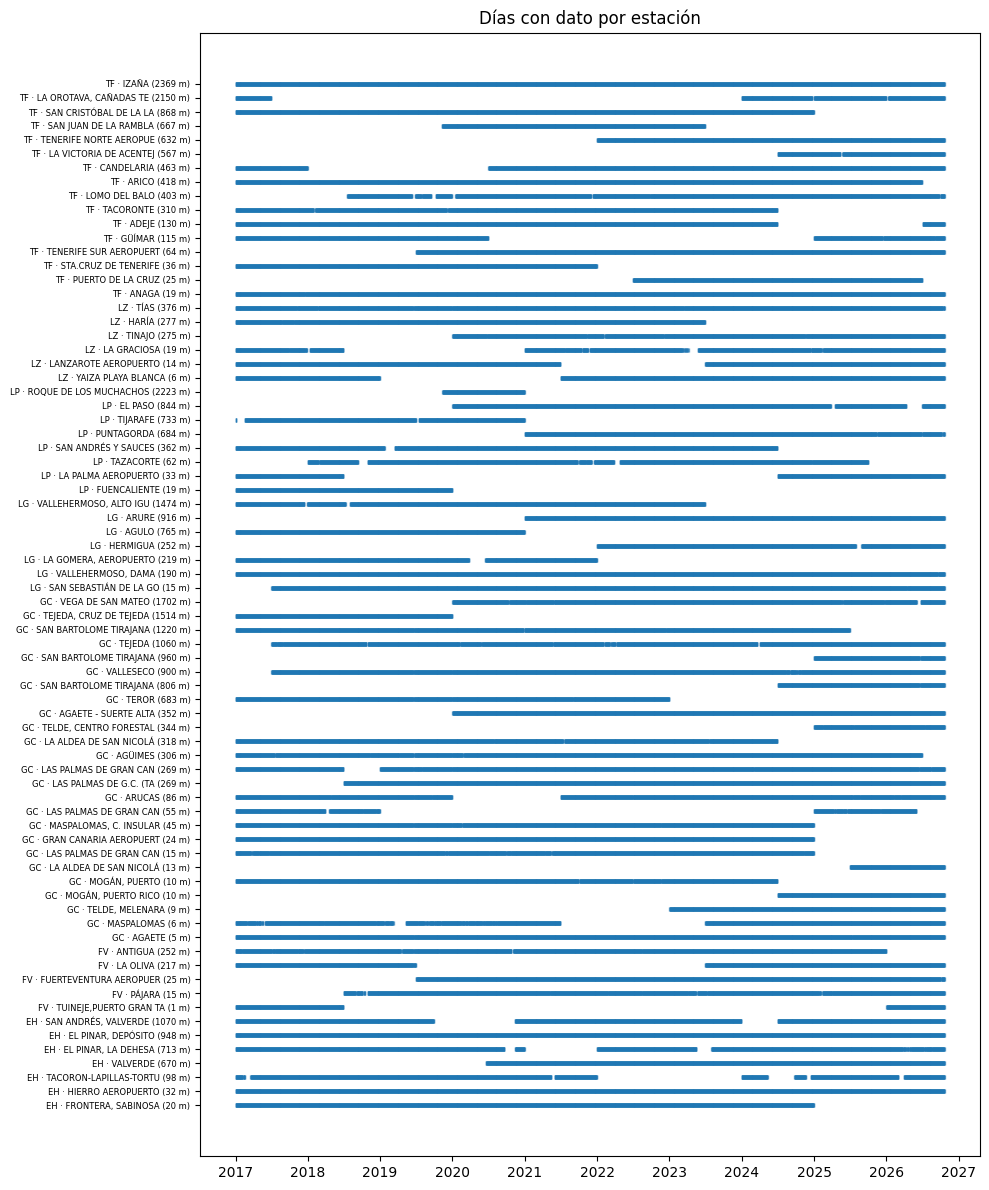

In [3]:
# Cobertura temporal: una línea por estación, ordenadas por isla y altitud
orden = dias.sort_values(["isla", "altitud"])
fig, ax = plt.subplots(figsize=(10, 12))
for k, (ind, f) in enumerate(orden.iterrows()):
    fechas = meteo.loc[meteo["indicativo"] == ind, "fecha"]
    ax.plot(fechas, np.full(len(fechas), k), "|", ms=3, color="tab:blue", alpha=0.6)
ax.set_yticks(range(len(orden)))
SIGLAS = {"Tenerife": "TF", "Gran Canaria": "GC", "La Palma": "LP", "La Gomera": "LG",
          "El Hierro": "EH", "Lanzarote": "LZ", "Fuerteventura": "FV"}
ax.set_yticklabels([f"{SIGLAS.get(f.isla, '?')} · {f.nombre[:22]} ({f.altitud:.0f} m)" for f in orden.itertuples()], fontsize=6)
ax.set_title("Días con dato por estación")
plt.tight_layout(); plt.show()

## 3. El radiosondeo de Güímar: la inversión medida cada día

AEMET lanza un globo sonda cada día desde Güímar (Tenerife). El Observatorio de Izaña publica sus datos completos en **PANGAEA**, mes a mes, con un nivel cada ~5 m: temperatura, punto de rocío y viento.

1. Busco los ficheros mensuales en el registro público de DOIs (**DataCite**).
2. Descargo cada mes, me quedo con el sondeo de mediodía (12 UTC, el más cercano a la hora de la temperatura máxima) y lo promedio en capas de 25 m para quitar el ruido del sensor.
3. Busco la **inversión** de cada día: la primera capa, entre 200 y 3.500 m, en la que la temperatura deja de bajar y sube al menos 0,5 °C.
   - **Base:** el punto más frío justo antes de que empiece a calentarse (el codo del perfil).
   - **Cima:** el punto más cálido de la capa.
   - **Intensidad:** cuántos grados sube.
4. Guardo cada mes procesado en Drive: si Colab se desconecta, al volver a ejecutar la celda continúa por donde iba.

*Datos: Torres, C. J. (AEMET), «Radiosonde measurements from station Izaña», PANGAEA, licencia BSRN.*

In [4]:
import re, requests

# 1) Ficheros mensuales disponibles, a través del registro público de DOIs (DataCite)
r = requests.get("https://api.datacite.org/dois",
                 params={"query": f'titles.title:"{TITULO_PANGAEA}"', "page[size]": 1000}, timeout=60)
r.raise_for_status()
meses = {}
for item in r.json()["data"]:
    titulo = item["attributes"]["titles"][0]["title"]
    m = re.search(r"Izaña \((\d{4})-(\d{2})\)", titulo)
    if m and titulo.startswith(TITULO_PANGAEA):
        meses[(int(m.group(1)), int(m.group(2)))] = item["id"]
inicio, fin = meteo["fecha"].min(), meteo["fecha"].max()
meses = {k: v for k, v in sorted(meses.items())
         if (inicio.year, inicio.month) <= k <= (fin.year, fin.month)}
print(f"Meses con radiosondeo en PANGAEA dentro del periodo: {len(meses)} "
      f"({min(meses)[0]}-{min(meses)[1]:02d} a {max(meses)[0]}-{max(meses)[1]:02d})")

# 2) Descarga y procesado mes a mes (se guarda cada mes; al reanudar, se salta lo hecho)
for (anio, mes), doi in meses.items():
    ruta_mes = os.path.join(RUTA_SONDEOS, f"{anio}-{mes:02d}.csv")
    if os.path.exists(ruta_mes):
        continue
    for intento in range(3):
        try:
            texto = requests.get(f"https://doi.pangaea.de/{doi}", params={"format": "textfile"}, timeout=300).text
            niveles = mr.leer_radiosondeo_pangaea(texto)
            break
        except Exception as e:
            print(f"  {anio}-{mes:02d}: intento {intento + 1} fallido ({e})")
            time.sleep(10)
    else:
        continue
    perfiles_mes, inv_mes = mr.perfiles_de_sondeo(niveles)
    perfiles_mes.merge(inv_mes, on="fecha", how="left").to_csv(ruta_mes, index=False)
    print(f"  {anio}-{mes:02d}: {inv_mes['fecha'].nunique()} sondeos de mediodía")

# 3) Uno todos los meses
todo = pd.concat([pd.read_csv(os.path.join(RUTA_SONDEOS, f), parse_dates=["fecha"])
                  for f in sorted(os.listdir(RUTA_SONDEOS)) if f.endswith(".csv")], ignore_index=True)
perfiles_sondeo = todo[["fecha", "altura_m", "temp_c", "td_c"]]
inversiones = todo.groupby("fecha", as_index=False)[["z_base", "z_cima", "intensidad"]].first()
print(f"\n{inversiones['fecha'].nunique()} días con sondeo de mediodía · "
      f"{perfiles_sondeo['altura_m'].min():.0f}–{perfiles_sondeo['altura_m'].max():.0f} m")

Meses con radiosondeo en PANGAEA dentro del periodo: 116 (2017-01 a 2026-08)
  2017-01: 30 sondeos de mediodía
  2017-02: 28 sondeos de mediodía
  2017-03: 29 sondeos de mediodía
  2017-04: 27 sondeos de mediodía
  2017-05: 31 sondeos de mediodía
  2017-06: 30 sondeos de mediodía
  2017-07: 30 sondeos de mediodía
  2017-08: 31 sondeos de mediodía
  2017-09: 28 sondeos de mediodía
  2017-10: 31 sondeos de mediodía
  2017-11: 29 sondeos de mediodía
  2017-12: 30 sondeos de mediodía
  2018-01: 31 sondeos de mediodía
  2018-02: 27 sondeos de mediodía
  2018-03: 27 sondeos de mediodía
  2018-04: 29 sondeos de mediodía
  2018-05: 31 sondeos de mediodía
  2018-06: 30 sondeos de mediodía
  2018-07: 31 sondeos de mediodía
  2018-08: 31 sondeos de mediodía
  2018-09: 29 sondeos de mediodía
  2018-10: 30 sondeos de mediodía
  2018-11: 19 sondeos de mediodía
  2018-12: 26 sondeos de mediodía
  2019-01: 30 sondeos de mediodía
  2019-02: 27 sondeos de mediodía
  2019-03: 30 sondeos de mediodía
  201

In [5]:
inversiones["mes"] = inversiones["fecha"].dt.month

print(f"Días con sondeo de mediodía: {len(inversiones)} · con inversión: "
      f"{inversiones['z_base'].notna().mean():.0%}")
clima = inversiones.groupby("mes").agg(
    porcentaje_con_inversion=("z_base", lambda z: round(100 * z.notna().mean())),
    base_mediana_m=("z_base", "median"), cima_mediana_m=("z_cima", "median"),
    intensidad_mediana_c=("intensidad", "median")).round(1)
clima

Días con sondeo de mediodía: 3400 · con inversión: 97%


,porcentaje_con_inversion,base_mediana_m,cima_mediana_m,intensidad_mediana_c
mes,,,,
1,95,1287.5,1537.5,2.9
2,89,1062.5,1337.5,2.4
3,95,1137.5,1387.5,3.0
4,98,1087.5,1362.5,3.0
5,100,1087.5,1412.5,3.7
6,100,937.5,1312.5,4.1
7,100,537.5,1075.0,5.5
8,99,612.5,1037.5,4.9
9,98,862.5,1287.5,4.0


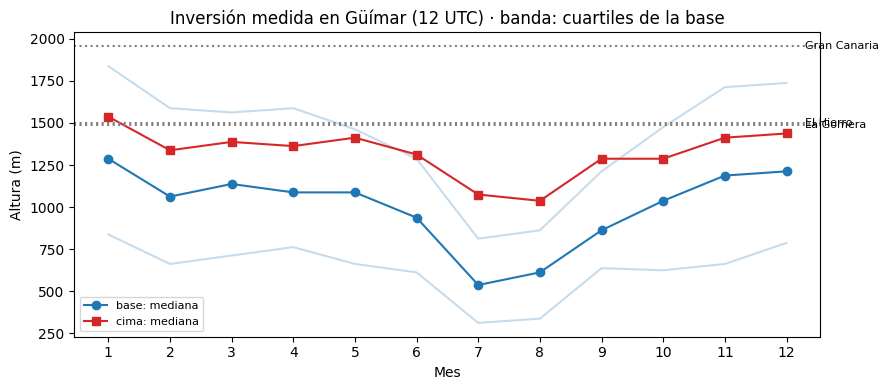

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for q, alpha in ((0.25, 0.25), (0.5, 1.0), (0.75, 0.25)):
    ax.plot(inversiones.groupby("mes")["z_base"].quantile(q), "o-" if q == 0.5 else "-",
            color="tab:blue", alpha=alpha, label="base: mediana" if q == 0.5 else None)
ax.plot(inversiones.groupby("mes")["z_cima"].median(), "s-", color="tab:red", label="cima: mediana")
for isla, techo in (("La Gomera", 1487), ("El Hierro", 1501), ("Gran Canaria", 1956)):
    ax.axhline(techo, ls=":", color="gray")
    ax.text(12.3, techo, isla, fontsize=8, va="center")
ax.set(xlabel="Mes", ylabel="Altura (m)", title="Inversión medida en Güímar (12 UTC) · banda: cuartiles de la base",
       xticks=range(1, 13))
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Un día de ejemplo: el perfil vertical

Para entender el método, tomo el día de verano con más estaciones en Tenerife y represento la temperatura máxima de cada estación frente a su altitud, con el perfil ajustado. Si el ajuste encuentra un **codo**, esa es la altura estimada de la inversión ese día. En verde, la inversión medida por el globo y el perfil del método `forma_sondeo`.

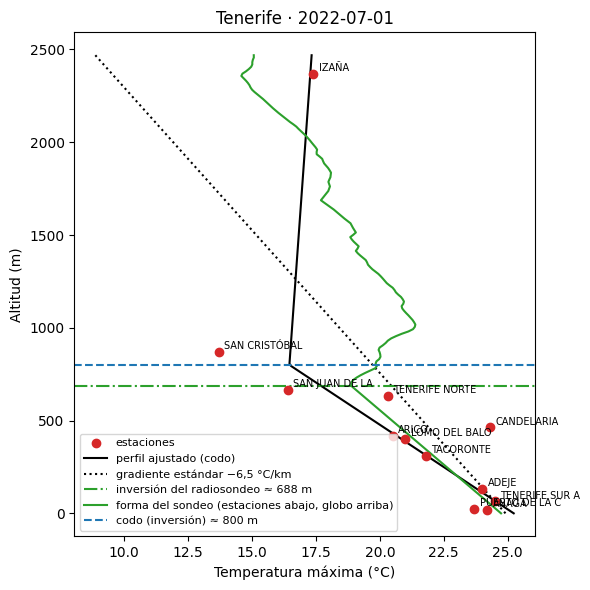

In [7]:
tf = meteo[(meteo["isla"] == "Tenerife") & meteo["fecha"].dt.month.isin([7, 8]) & meteo["tmax"].notna()]
dia = tf.groupby("fecha").size().idxmax()
g = tf[tf["fecha"] == dia]

perfil = mr.ajustar_perfil(g["altitud"], g["tmax"])
z = np.linspace(0, g["altitud"].max() + 100, 200)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(g["tmax"], g["altitud"], color="tab:red", zorder=3, label="estaciones")
ax.plot(mr.evaluar_perfil(perfil, z), z, "k-", label=f"perfil ajustado ({perfil['tipo']})")
ax.plot(g["tmax"].max() + mr.GRADIENTE_ESTANDAR * (z - g.loc[g["tmax"].idxmax(), "altitud"]), z, "k:",
        label="gradiente estándar −6,5 °C/km")
inv_dia = inversiones.loc[inversiones["fecha"] == dia, "z_base"]
if len(inv_dia) and np.isfinite(inv_dia.iloc[0]):
    ax.axhline(inv_dia.iloc[0], color="tab:green", ls="-.", label=f"inversión del radiosondeo ≈ {inv_dia.iloc[0]:.0f} m")
    s = perfiles_sondeo[perfiles_sondeo["fecha"] == dia].sort_values("altura_m")
    forma = [mr.estimar_con_forma_del_sondeo(zz, g["altitud"], g["tmax"], s["altura_m"], s["temp_c"],
                                             inv_dia.iloc[0]) for zz in z]
    ax.plot(forma, z, color="tab:green", label="forma del sondeo (estaciones abajo, globo arriba)")
if perfil["z_codo"]:
    ax.axhline(perfil["z_codo"], color="tab:blue", ls="--", label=f"codo (inversión) ≈ {perfil['z_codo']:.0f} m")
for r in g.itertuples():
    ax.annotate(r.nombre[:14], (r.tmax, r.altitud), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set(xlabel="Temperatura máxima (°C)", ylabel="Altitud (m)", title=f"Tenerife · {dia:%Y-%m-%d}")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 5. La inversión vista por las estaciones

Ajusto el perfil de temperatura máxima cada día en cada isla con todas sus estaciones y cuento cuántos días aparece un codo y a qué altura. En islas con pocas estaciones de altura (Lanzarote, Fuerteventura) el método no debería encontrar codos: no hay datos para verlos.

In [8]:
perfiles = mr.perfiles_diarios(meteo, "tmax")
perfiles["mes"] = pd.to_datetime(perfiles["fecha"]).dt.month

resumen_codo = perfiles.groupby("isla").agg(
    dias=("tipo", "size"),
    porcentaje_con_codo=("tipo", lambda t: round(100 * (t == "codo").mean(), 1)),
    altura_codo_mediana=("z_codo", "median"),
    gradiente_mediano_por_km=("pendiente_por_km", "median"))
resumen_codo.round(2)

,dias,porcentaje_con_codo,altura_codo_mediana,gradiente_mediano_por_km
isla,,,,
El Hierro,3581,33.6,600.0,-6.54
Fuerteventura,1143,0.0,NaN,-5.08
Gran Canaria,3582,17.4,800.0,-2.96
La Gomera,3402,28.3,700.0,-6.74
La Palma,2858,49.9,500.0,-7.68
Lanzarote,3204,0.0,NaN,-7.87
Tenerife,3582,52.2,800.0,-7.12


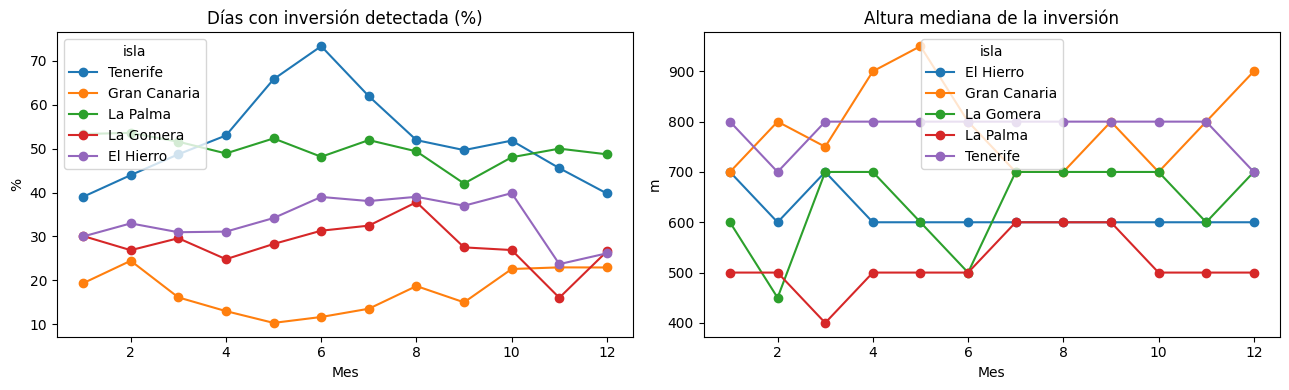

In [9]:
con_codo = perfiles[perfiles["tipo"] == "codo"]
islas_codo = [i for i in ("Tenerife", "Gran Canaria", "La Palma", "La Gomera", "El Hierro")
              if (con_codo["isla"] == i).sum() > 30]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
(perfiles.assign(codo=perfiles["tipo"] == "codo").groupby(["mes", "isla"])["codo"].mean().unstack()[islas_codo] * 100
 ).plot(ax=ejes[0], marker="o")
ejes[0].set(title="Días con inversión detectada (%)", xlabel="Mes", ylabel="%")
con_codo[con_codo["isla"].isin(islas_codo)].groupby(["mes", "isla"])["z_codo"].median().unstack().plot(ax=ejes[1], marker="o")
ejes[1].set(title="Altura mediana de la inversión", xlabel="Mes", ylabel="m")
plt.tight_layout(); plt.show()

### ¿Coincide la inversión que "ven" las estaciones con la que mide el globo?

Comparo, día a día, la altura del codo detectado con las estaciones de cada isla con la base de la inversión del radiosondeo. Si el método de las estaciones funciona, ambas alturas deberían parecerse en las islas con estaciones a media altura (como Gran Canaria). En Tenerife, por el hueco de estaciones entre 870 y 2.150 m, se espera que no.

In [10]:
comp = con_codo.merge(inversiones[["fecha", "z_base"]], on="fecha", how="inner").dropna(subset=["z_base"])
comp["diferencia_m"] = comp["z_codo"] - comp["z_base"]
resumen_comp = comp.groupby("isla").agg(dias=("diferencia_m", "size"),
                                        diferencia_mediana_m=("diferencia_m", "median"),
                                        diferencia_absoluta_mediana_m=("diferencia_m", lambda d: d.abs().median()),
                                        correlacion=("z_codo", lambda s: s.corr(comp.loc[s.index, "z_base"])))
resumen_comp.round(2)

,dias,diferencia_mediana_m,diferencia_absoluta_mediana_m,correlacion
isla,,,,
El Hierro,1123,-187.5,312.5,0.04
Gran Canaria,549,162.5,362.5,0.19
La Gomera,897,-137.5,312.5,-0.17
La Palma,1334,-412.5,437.5,-0.13
Tenerife,1755,-262.5,387.5,-0.04


## 6. Validación dejando una estación fuera

Para cada día y cada estación: la escondo, la estimo con las demás de su isla con los ocho métodos y guardo el valor real y el estimado. Variables: temperatura máxima (`tmax`, °C), humedad relativa media (`hrMedia`, %) y viento medio (`velmedia`, m/s).

Con todos los días tarda varios minutos; `PASO_DIAS = 2` o `3` lo acelera. Los resultados se guardan en Drive para no repetirlo.

In [11]:
ruta_res = os.path.join(RUTA_RESULTADOS, f"validacion_paso{PASO_DIAS}_alta_resolucion.csv")
if os.path.exists(ruta_res):
    res = pd.read_csv(ruta_res, parse_dates=["fecha"])
    print("Resultados cargados de Drive")
else:
    t0 = time.time()
    res = mr.validacion_dejando_una_fuera(meteo, paso_dias=PASO_DIAS,
                                         inversiones=inversiones.set_index("fecha")["z_base"],
                                         perfiles_sondeo=perfiles_sondeo)
    res.to_csv(ruta_res, index=False)
    print(f"Validación completada en {(time.time() - t0) / 60:.1f} min")
print(f"{len(res):,} estimaciones")

Validación completada en 14.5 min
3,340,191 estimaciones


## 7. Resultados: ¿qué método se equivoca menos?

- **MAE:** error absoluto medio (en °C, % o m/s).
- **Sesgo:** error medio con signo. Positivo = el método sobrestima.

In [12]:
tabla = mr.resumen_errores(res, UMBRAL_ALTURA)
mae = tabla.pivot_table(index=["variable", "franja"], columns="metodo", values="MAE")
mae = mae[[m for m in mr.METODOS if m in mae.columns]]
mae.round(2)

metodo              cercana  gradiente_fijo  perfil_dia  perfil_residuos  \
variable franja                                                            
hrMedia  < 1000 m     13.51           14.25        8.84             7.98   
         >= 1000 m    19.60           24.69       22.16            22.30   
         todas        14.22           15.47       10.40             9.66   
tmax     < 1000 m      3.30            2.43        1.86             1.70   
         >= 1000 m     4.98            3.04        4.67             4.69   
         todas         3.51            2.51        2.22             2.07   
velmedia < 1000 m      1.87             NaN        1.87             1.75   
         >= 1000 m     2.08             NaN        2.92             2.94   
         todas         1.90             NaN        2.00             1.90   

metodo              perfil_sondeo  perfil_sondeo_residuos  forma_sondeo  \
variable franja                                                           
hrMedia  < 1000 m            9.33                    8.61          9.17   
         >= 1000 m          20.67                   20.75         18.92   
         todas              10.66                   10.03         10.31   
tmax     < 1000 m            1.83                    1.66          1.87   
         >= 1000 m           4.00                    4.02          3.03   
         todas               2.11                    1.95          2.02   
velmedia < 1000 m            1.90                    1.78           NaN   
         >= 1000 m           2.58                    2.59           NaN   
         todas               1.98                    1.88           NaN   

metodo              forma_sondeo_residuos  
variable franja                            
hrMedia  < 1000 m                   10.70  
         >= 1000 m                  18.73  
         todas                      11.64  
tmax     < 1000 m                    1.70  
         >= 1000 m                   2.65  
         todas                       1.82  
velmedia < 1000 m                     NaN  
         >= 1000 m                    NaN  
         todas                        NaN

In [13]:
sesgo = tabla.pivot_table(index=["variable", "franja"], columns="metodo", values="sesgo")
sesgo[[m for m in mr.METODOS if m in sesgo.columns]].round(2)

metodo              cercana  gradiente_fijo  perfil_dia  perfil_residuos  \
variable franja                                                            
hrMedia  < 1000 m     -1.84           -6.16       -0.91            -0.15   
         >= 1000 m     5.46           15.81        6.65             6.12   
         todas        -0.98           -3.59       -0.03             0.59   
tmax     < 1000 m     -1.18            0.63        0.07            -0.04   
         >= 1000 m     2.59           -1.10        0.07             0.15   
         todas        -0.71            0.41        0.07            -0.02   
velmedia < 1000 m      0.46             NaN       -0.06            -0.04   
         >= 1000 m    -1.23             NaN       -0.70            -0.62   
         todas         0.24             NaN       -0.14            -0.12   

metodo              perfil_sondeo  perfil_sondeo_residuos  forma_sondeo  \
variable franja                                                           
hrMedia  < 1000 m           -0.75                    0.07         -2.43   
         >= 1000 m           9.88                    8.98         -7.87   
         todas               0.49                    1.11         -3.07   
tmax     < 1000 m            0.03                   -0.09          0.18   
         >= 1000 m          -0.34                   -0.25          1.01   
         todas              -0.02                   -0.11          0.28   
velmedia < 1000 m           -0.06                   -0.04           NaN   
         >= 1000 m          -0.90                   -0.83           NaN   
         todas              -0.17                   -0.14           NaN   

metodo              forma_sondeo_residuos  
variable franja                            
hrMedia  < 1000 m                    2.82  
         >= 1000 m                  -4.33  
         todas                       1.98  
tmax     < 1000 m                   -0.26  
         >= 1000 m                   0.46  
         todas                      -0.16  
velmedia < 1000 m                     NaN  
         >= 1000 m                    NaN  
         todas                        NaN

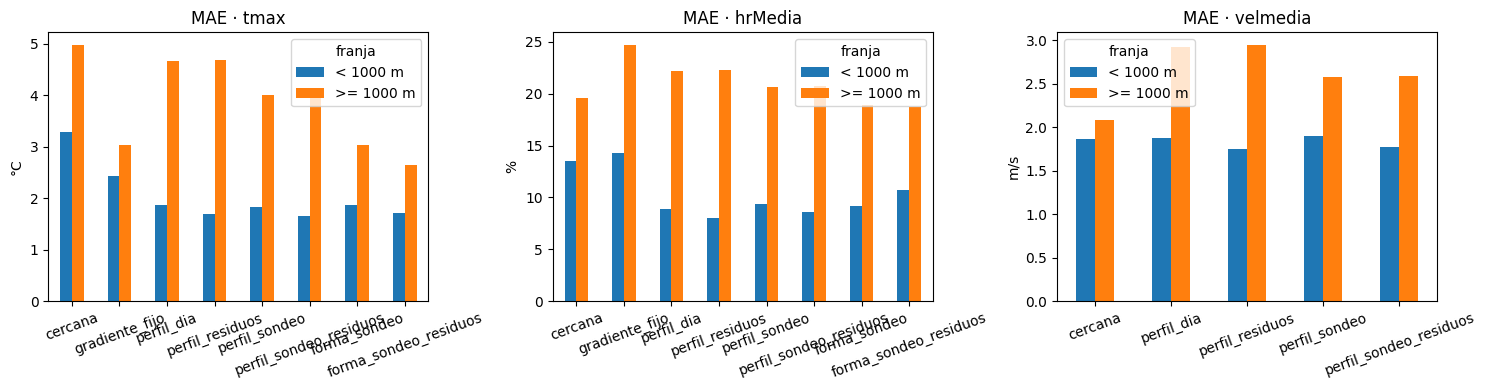

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (var, unidad) in zip(ejes, [("tmax", "°C"), ("hrMedia", "%"), ("velmedia", "m/s")]):
    t = tabla[(tabla["variable"] == var) & (tabla["franja"] != "todas")]
    t.pivot(index="metodo", columns="franja", values="MAE").reindex(
        [m for m in mr.METODOS if m in set(t["metodo"])]).plot.bar(ax=ax, rot=20)
    ax.set(title=f"MAE · {var}", ylabel=unidad, xlabel="")
plt.tight_layout()
plt.savefig(os.path.join(RUTA_RESULTADOS, "mae_por_metodo.png"), dpi=150)
plt.show()

### La prueba más dura: estaciones de altura

Error de temperatura máxima y de humedad en cada estación por encima de 1.000 m. Aquí se ve si algún método estima bien, por ejemplo, Izaña o Las Cañadas sin usarlas.

In [15]:
altas = res[res["altitud"] >= UMBRAL_ALTURA]
por_estacion = (altas.groupby(["variable", "indicativo", "metodo"])["error"].apply(lambda e: e.abs().mean())
                .unstack("metodo")[list(mr.METODOS)])
por_estacion = por_estacion.join(dias[["nombre", "isla", "altitud"]], on="indicativo")
for var in ("tmax", "hrMedia"):
    print(f"\nMAE por estación de altura · {var}")
    print(por_estacion.loc[var].sort_values("altitud", ascending=False).round(2).to_string())


MAE por estación de altura · tmax
            cercana  gradiente_fijo  perfil_dia  perfil_residuos  perfil_sondeo  perfil_sondeo_residuos  forma_sondeo  forma_sondeo_residuos                                    nombre          isla  altitud
indicativo                                                                                                                                                                                                   
C430E          8.25            5.54       10.91            10.81           8.46                    8.37          2.93                   2.54                                     IZAÑA      Tenerife     2369
C101A          6.45            4.02       15.59            15.60          10.74                   10.74          2.61                   2.44                    ROQUE DE LOS MUCHACHOS      La Palma     2223
C406G          4.67            6.89        3.48             3.23           3.72                    3.42          3.70                   3.26 

### Por isla

In [16]:
(res[res["variable"] == "tmax"].groupby(["isla", "metodo"])["error"].apply(lambda e: e.abs().mean())
 .unstack()[list(mr.METODOS)].round(2))

metodo,cercana,gradiente_fijo,perfil_dia,perfil_residuos,perfil_sondeo,perfil_sondeo_residuos,forma_sondeo,forma_sondeo_residuos
isla,,,,,,,,
El Hierro,4.11,2.51,2.35,2.37,2.01,2.02,1.91,1.95
Fuerteventura,1.80,1.76,1.27,1.31,1.27,1.31,1.26,1.30
Gran Canaria,2.41,2.04,1.88,1.54,1.86,1.48,1.98,1.59
La Gomera,5.36,3.06,2.78,2.71,2.61,2.54,2.88,2.58
La Palma,3.67,2.85,2.85,2.82,2.66,2.64,2.32,2.22
Lanzarote,2.22,1.64,1.74,1.76,1.94,1.96,1.70,1.71
Tenerife,4.70,3.31,2.53,2.41,2.32,2.22,1.88,1.76


## 8. Conclusiones

> Rellenar tras ejecutar con los datos reales:
>
> - Qué método tiene menor error para cada variable, en general y en las estaciones de altura.
> - Cuánto mejora respecto a copiar la estación más cercana.
> - Si la inversión detectada tiene sentido físico (porcentaje de días, altura y estacionalidad).
> - Qué método se usará para asignar la meteorología a las parcelas del dataset de incendios.